# Chapter 12 – Example 12.2

## Sensitivity Analysis: Spearman Correlation

**Objective:** Identify which Genetic Algorithm hyperparameters ($N_{pop}$, $N_{gen}$, $p_m$, $p_c$) have the greatest influence on the performance metrics (error, time, variability).

### 1. Design of Experiments and Metrics Simulation

In [10]:
from numpy import *

# Set random seed for reproducibility
random.seed(99)

# Design of experiments: [N_pop, N_gen, p_m, p_c]
experiments = array([
    [10, 20, 0.05, 0.7],
    [15, 25, 0.10, 0.8],
    [20, 30, 0.15, 0.9],
    [25, 35, 0.20, 0.7],
    [30, 40, 0.25, 0.8],
    [10, 40, 0.10, 0.9],
    [20, 20, 0.20, 0.7],
    [25, 25, 0.05, 0.8],
])

N_EXP = len(experiments)
n_pop_arr = experiments[:, 0]
n_gen_arr = experiments[:, 1]
pm_arr = experiments[:, 2]

# Metric models (simplified for simulation)
final_error = 80. / (n_pop_arr * n_gen_arr)**0.35 + 2. * pm_arr + random.normal(0, 0.5, N_EXP)
time_ms = 0.12 * n_pop_arr * n_gen_arr + random.normal(0, 2, N_EXP)
variability = 15. / (n_pop_arr**0.5) + 5. * pm_arr + random.normal(0, 1, N_EXP)

# Stack of metrics and names
metrics = stack([final_error, time_ms, variability], axis=1)
metric_names = ['Final error (mm)', 'Time (ms)', 'Variability']
param_names = ['N_pop', 'N_gen', 'p_m', 'p_c']

# Display results table
print("Experiments and Metrics Table")
print("=" * 62)
print(f"{'N_pop':>6} {'N_gen':>6} {'p_m':>6} {'p_c':>6} | {'Error':>10} {'Time':>10} {'Var':>10}")
print("-" * 62)
for i in range(N_EXP):
    e = experiments[i]
    m = metrics[i]
    print(f"{e[0]:>6.0f} {e[1]:>6.0f} {e[2]:>6.2f} {e[3]:>6.2f} | {m[0]:>10.2f} {m[1]:>10.2f} {m[2]:>10.2f}")
print("=" * 62)

Experiments and Metrics Table
 N_pop  N_gen    p_m    p_c |      Error       Time        Var
--------------------------------------------------------------
    10     20   0.05   0.70 |      12.55      23.77       5.88
    15     25   0.10   0.80 |      11.28      40.26       3.79
    20     30   0.15   0.90 |       8.97      71.67       3.60
    25     35   0.20   0.70 |       8.54     106.37       4.59
    30     40   0.25   0.80 |       7.11     144.05       3.26
    10     40   0.10   0.90 |       9.99      48.91       5.51
    20     20   0.20   0.70 |      10.60      48.54       3.50
    25     25   0.05   0.80 |       8.92      72.13       3.06


### 2. Spearman Correlation Calculation

Spearman's correlation evaluates the monotonic relationship between two variables using their ranks.

In [11]:
def spearman_corr(x, y):
    """Calculates the Spearman correlation coefficient between x and y."""
    n = len(x)
    rx = argsort(argsort(x)) + 1
    ry = argsort(argsort(y)) + 1
    d = rx - ry
    return 1 - 6 * sum(d**2) / (n * (n**2 - 1))

# Display correlation matrix in text format
print("Spearman Correlation: Parameters x Metrics")
print("=" * 56)
print(f"{'Parameter':<12}", end="")
for m in metric_names:
    print(f" | {m[:12]:>11}", end="")
print("\n" + "-" * 56)

for j, p in enumerate(param_names):
    print(f"{p:<12}", end="")
    for k in range(3):
        r = spearman_corr(experiments[:, j], metrics[:, k])
        print(f" | {r:>11.3f}", end="")
    print()
print("=" * 56)

Spearman Correlation: Parameters x Metrics
Parameter    | Final error  |   Time (ms) | Variability
--------------------------------------------------------
N_pop        |      -0.857 |       0.857 |      -0.833
N_gen        |      -0.714 |       0.714 |      -0.095
p_m          |      -0.548 |       0.548 |      -0.429
p_c          |      -0.357 |       0.357 |      -0.286


### 3. Visualization with Heatmap

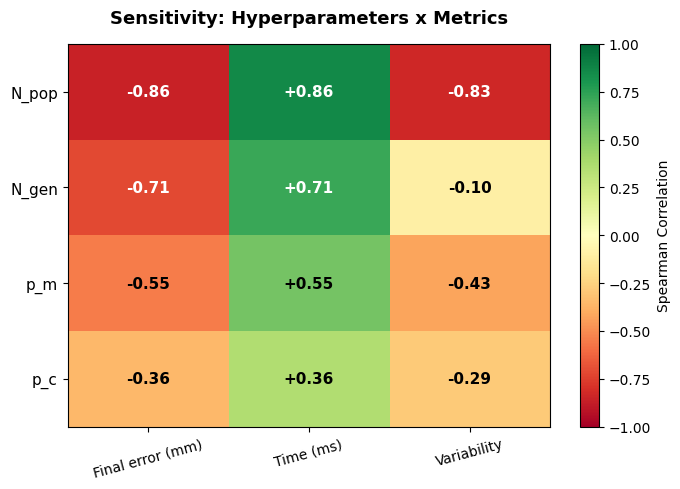

Conclusion: N_pop is the most influential hyperparameter on error (negatively) and time (positively).


In [12]:
import matplotlib.pyplot as plt

# Initialize correlation matrix
corr_mat = zeros((len(param_names), len(metric_names)))
for j in range(len(param_names)):
    for k in range(len(metric_names)):
        corr_mat[j, k] = spearman_corr(experiments[:, j], metrics[:, k])

# Plot heatmap
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr_mat, cmap='RdYlGn', vmin=-1, vmax=1, aspect='auto')

# Configure colorbar and labels
plt.colorbar(im, ax=ax, label='Spearman Correlation')
ax.set_xticks(range(len(metric_names)))
ax.set_xticklabels(metric_names, fontsize=10, rotation=15)
ax.set_yticks(range(len(param_names)))
ax.set_yticklabels(param_names, fontsize=11)

ax.set_title('Sensitivity: Hyperparameters x Metrics', fontsize=13, fontweight='bold', pad=15)

# Add text values inside cells
for i in range(len(param_names)):
    for k in range(len(metric_names)):
        v = corr_mat[i, k]
        clr = 'white' if abs(v) > 0.55 else 'black'
        ax.text(k, i, f'{v:+.2f}', ha='center', va='center',
                fontsize=11, fontweight='bold', color=clr)

plt.tight_layout()
plt.savefig('fig12_2_spearman.png', dpi=150, bbox_inches='tight')
plt.show()

# Quick conclusion
print("Conclusion: N_pop is the most influential hyperparameter on error (negatively) and time (positively).")